In [2]:
import sys, json, time
sys.path.append("../src")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from features import RAW_FEATURES
from metrics import evaluate
from drift import feature_psi
from monitor import check_rules_v2, group_psi, RULES_V2
from reference import build_reference
from retrain import train_challenger, matured_end
from simulate import run_policy

feat = pd.read_parquet("../data/processed/features.parquet")
champion = joblib.load("../models/champion_v1.joblib")
ref_v1 = json.load(open("../models/reference_stats.json"))
registry = json.load(open("../models/registry.json"))

THR = registry[0]["threshold"]
REVIEW_COST = registry[0]["review_cost"]
BASE = registry[0]["val_metrics"]["pr_auc"]

prod = feat[feat.split == "prod"].copy()
prod["s_v1"] = champion.predict_proba(prod[RAW_FEATURES])[:, 1]
models = {"v1": champion}
print(THR, REVIEW_COST, BASE)

0.0173 5.0 0.6295


In [3]:
rows = []
for w in range(12):
    b = prod[prod.batch == w]
    fp = feature_psi(b[RAW_FEATURES], ref_v1)
    rows.append({"week": w, **{g: round(v, 2) for g, v in group_psi(fp).items()}})
pd.DataFrame(rows)

,week,M,D,C,card_addr,amount_product,email
0,0,0.72,0.53,0.24,0.26,0.33,0.18
1,1,0.63,0.57,0.21,0.07,0.26,0.28
2,2,0.78,0.59,0.15,0.03,0.23,0.08
3,3,0.74,0.53,0.14,0.03,0.24,0.07
4,4,0.83,0.68,0.18,0.06,0.24,0.10
5,5,0.90,0.33,0.22,0.10,0.23,0.12
6,6,0.58,0.42,0.18,0.05,0.21,0.11
7,7,0.68,0.66,0.22,0.06,0.22,0.12
8,8,0.81,0.70,0.22,0.05,0.22,0.12
9,9,0.91,0.77,0.24,0.12,0.22,0.12


In [4]:
chall = {}
for w in range(11):                    # weeks 0-10; after week 11 there is no future week to serve
    t0 = time.time()
    model, tr_w, ho_w = train_challenger(feat, w)

    assert tr_w.day.max() < ho_w.day.min()          # training stops before the holdout starts
    assert ho_w.day.max() < matured_end(w)          # nothing newer than the labels we could know

    key = f"c{w}"
    ho_scores = model.predict_proba(ho_w[RAW_FEATURES])[:, 1]
    imp = pd.Series(model.booster_.feature_importance(importance_type="gain"), index=RAW_FEATURES)
    chall[w] = {"key": key, "model": model, "holdout": ho_w,
                "train_days": [float(tr_w.day.min()), float(tr_w.day.max())],
                "ref": build_reference(tr_w[RAW_FEATURES], RAW_FEATURES, ho_scores, imp)}
    models[key] = model
    prod["s_" + key] = model.predict_proba(prod[RAW_FEATURES])[:, 1]
    print(w, "| train days", chall[w]["train_days"], "| holdout rows", len(ho_w), "| %.0fs" % (time.time() - t0))

0 | train days [9.00005787037037, 68.99951388888888] | holdout rows 40887 | 10s
1 | train days [16.000266203703703, 75.99986111111112] | holdout rows 41668 | 11s
2 | train days [23.00019675925926, 82.99982638888889] | holdout rows 49336 | 9s
3 | train days [30.000162037037036, 89.99998842592592] | holdout rows 49909 | 11s
4 | train days [37.00010416666667, 96.99986111111112] | holdout rows 42523 | 9s
5 | train days [44.00017361111111, 103.99986111111112] | holdout rows 41639 | 8s
6 | train days [51.00020833333333, 110.99938657407408] | holdout rows 44540 | 7s
7 | train days [58.00012731481481, 117.99962962962962] | holdout rows 43873 | 7s
8 | train days [65.00002314814814, 124.99981481481481] | holdout rows 38950 | 7s
9 | train days [72.00010416666667, 131.99994212962963] | holdout rows 36852 | 7s
10 | train days [79.00017361111111, 138.9998148148148] | holdout rows 38502 | 8s


In [5]:
json.dump(RULES_V2, open("../models/monitor_rules_v2.json", "w"), indent=2)

def never(w, st, fp, sc, pooled):
    return []

def every_4_weeks(w, st, fp, sc, pooled):
    return ["schedule"] if w in (3, 7) else []

def on_alert(w, st, fp, sc, pooled):
    return check_rules_v2(fp, sc, pooled, st["baseline"])

v1_info = {"ref": ref_v1, "thr": THR, "baseline": BASE}

results, events = {}, {}
for name, trig in [("never retrain", never), ("every 4 weeks", every_4_weeks), ("on alert", on_alert)]:
    results[name], events[name] = run_policy(prod, models, chall, trig, v1_info, REVIEW_COST)

In [6]:
d5 = pd.read_csv("../docs/day5_monitor_log.csv")
a = results["never retrain"]
print("PR-AUC matches Day 5:", np.allclose(a.pr_auc, d5.pr_auc_true, atol=1e-4))
print("Net benefit matches Day 5:", np.allclose(a.net_benefit, d5.net_benefit, atol=0.5))

PR-AUC matches Day 5: True
Net benefit matches Day 5: True


In [7]:
cmp_table = pd.DataFrame({n: r.set_index("week")["pr_auc"] for n, r in results.items()})
cmp_table.round(3)

,never retrain,every 4 weeks,on alert
week,,,
0,0.467,0.467,0.467
1,0.476,0.476,0.484
2,0.570,0.570,0.566
3,0.614,0.614,0.601
4,0.518,0.544,0.536
5,0.543,0.553,0.575
6,0.456,0.505,0.515
7,0.417,0.408,0.412
8,0.427,0.459,0.459


In [8]:
totals = pd.DataFrame({
    n: {"attempts": len(events[n]),
        "promotions": int(events[n]["promoted"].sum()) if len(events[n]) else 0,
        "mean weekly PR-AUC": r.pr_auc.mean(),
        "total net benefit": r.net_benefit.sum()}
    for n, r in results.items()}).T
totals.round(3)

,attempts,promotions,mean weekly PR-AUC,total net benefit
never retrain,0.0,0.0,0.493,866880.01
every 4 weeks,2.0,2.0,0.510,919707.98
on alert,4.0,4.0,0.512,908121.77


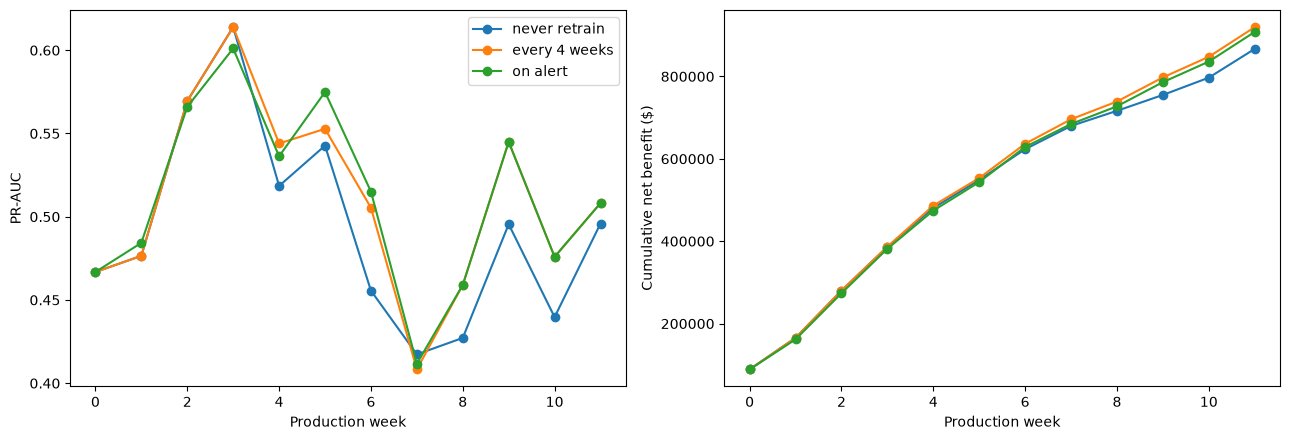

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for n, r in results.items():
    ax[0].plot(r.week, r.pr_auc, marker="o", label=n)
    ax[1].plot(r.week, r.net_benefit.cumsum(), marker="o", label=n)
ax[0].set_xlabel("Production week"); ax[0].set_ylabel("PR-AUC"); ax[0].legend()
ax[1].set_xlabel("Production week"); ax[1].set_ylabel("Cumulative net benefit ($)")
plt.tight_layout(); plt.show()

In [10]:
for n, e in events.items():
    print("\n" + n)
    print(e.round(3).to_string(index=False) if len(e) else "  no retrain attempts")


never retrain
  no retrain attempts

every 4 weeks
 week  reasons champion challenger  pooled_pr_auc  champ_holdout_pr_auc  chall_holdout_pr_auc  chall_threshold  promoted
    3 schedule       v1         c3          0.470                 0.470                 0.540            0.023      True
    7 schedule       c3         c7          0.547                 0.547                 0.635            0.028      True

on alert
 week       reasons champion challenger pooled_pr_auc  champ_holdout_pr_auc  chall_holdout_pr_auc  chall_threshold  promoted
    0 feature drift       v1         c0          None                 0.623                 0.676            0.023      True
    2 feature drift       c0         c2          None                 0.513                 0.545            0.017      True
    4 feature drift       c2         c4          None                 0.542                 0.583            0.015      True
    7 feature drift       c4         c7          None                 0.566

In [11]:
serving = results["on alert"].set_index("week")["model"]
refs = {"v1": ref_v1, **{c["key"]: c["ref"] for c in chall.values()}}

rows = []
for w in range(12):
    b = prod[prod.batch == w]
    fp = feature_psi(b[RAW_FEATURES], refs[serving[w]])
    rows.append({"week": w, "model": serving[w], **{g: round(v, 2) for g, v in group_psi(fp).items()}})
pd.DataFrame(rows)

,week,model,M,D,C,card_addr,amount_product,email
0,0,v1,0.72,0.53,0.24,0.26,0.33,0.18
1,1,c0,0.55,0.50,0.20,0.07,0.21,0.27
2,2,c0,0.70,0.52,0.13,0.03,0.18,0.08
3,3,c2,0.45,0.33,0.08,0.02,0.06,0.02
4,4,c2,0.52,0.45,0.07,0.03,0.05,0.03
5,5,c4,0.32,0.28,0.03,0.02,0.00,0.01
6,6,c4,0.20,0.14,0.03,0.02,0.00,0.01
7,7,c4,0.31,0.27,0.04,0.02,0.00,0.01
8,8,c7,0.10,0.12,0.02,0.03,0.01,0.01
9,9,c7,0.13,0.16,0.03,0.02,0.01,0.02


In [12]:
def pooled_by_product(policy, weeks=range(4, 12)):
    served = results[policy].set_index("week")["model"]
    out = {}
    for prod_code in ["W", "C", "H", "S", "R"]:
        ys, ss = [], []
        for w in weeks:
            g = prod[(prod.batch == w) & (prod.ProductCD == prod_code)]
            ys.append(g.isFraud.to_numpy())
            ss.append(g["s_" + served[w]].to_numpy())
        out[prod_code] = evaluate(np.concatenate(ys), np.concatenate(ss))["pr_auc"]
    return out

pd.DataFrame({name: pooled_by_product(name) for name in results}).round(3)

,never retrain,every 4 weeks,on alert
W,0.117,0.181,0.189
C,0.757,0.752,0.754
H,0.565,0.592,0.592
S,0.372,0.519,0.498
R,0.765,0.755,0.754


Over the 12 production weeks, mean weekly PR-AUC was 0.493 with no retraining, 0.510 with a scheduled retrain every 4 weeks (2 promotions), and 0.512 with alert-triggered retraining (4 promotions). Total net benefit was $866,880, $919,708 and $908,122, so retraining improved net benefit by 5-6% under the assumed $5 review cost. Retraining did not restore validation-level performance (0.63). Alert-triggered retraining did not beat scheduled retraining. All four alerts were feature-drift alerts, because the performance rule needs two matured weeks of the current model and never had enough. Every challenger passed the promotion guard by a wide margin, so the guard was not exercised. Results come from one run and weekly PR-AUC varies by 0.05-0.1, so small differences are not conclusive.

Group PSI against the serving model’s reference fell as references became more recent: for the M group, from 0.72 (v1) to 0.45-0.52 (c2), 0.20-0.32 (c4) and 0.04-0.13 (c7). The drift rule’s condition held in 7 of 12 weeks (0, 1, 2, 3, 4, 5, 7), but retrains occurred only at weeks 0, 2, 4 and 7 because of the 2-week minimum gap. From week 8, with c7 serving, no feature group exceeded 0.25. Pooled over weeks 4-11, retraining raised PR-AUC for product W from 0.117 to 0.181-0.189 (about +55-60%) and left C (0.757 to 0.752-0.754) and R (0.765 to 0.754-0.755) essentially unchanged. W remains well below its validation PR-AUC of 0.313.

In [13]:
pd.concat(results, names=["policy"]).reset_index(level=0).to_csv("../docs/day6_weekly_by_policy.csv", index=False)
ev = {n: e for n, e in events.items() if len(e)}
if ev:
    pd.concat(ev, names=["policy"]).reset_index(level=0).to_csv("../docs/day6_events.csv", index=False)

In [14]:
if len(events["on alert"]):
    reg = json.load(open("../models/registry.json"))
    for _, e in events["on alert"].iterrows():
        if e["promoted"]:
            reg[-1]["status"] = "retired"
            key = e["challenger"]
            joblib.dump(models[key], f"../models/{key}.joblib")
            reg.append({"version": key, "promoted_end_of_week": int(e["week"]),
                        "trained_on_days": chall[int(e["week"])]["train_days"],
                        "threshold": float(e["chall_threshold"]),
                        "holdout_pr_auc": float(e["chall_holdout_pr_auc"]),
                        "reasons": e["reasons"], "status": "champion (simulated)"})
    json.dump(reg, open("../models/registry.json", "w"), indent=2)

In [15]:
import os
os.makedirs("../docs/img", exist_ok=True)

serving = results["on alert"].set_index("week")["model"]
refs = {"v1": ref_v1, **{c["key"]: c["ref"] for c in chall.values()}}

rows = []
for w in range(12):
    b = prod[prod.batch == w]
    fp = feature_psi(b[RAW_FEATURES], refs[serving[w]])
    rows.append({"week": w, "model": serving[w],
                 **{g: round(v, 3) for g, v in group_psi(fp).items()}})

gp_table = pd.DataFrame(rows)
gp_table.to_csv("../docs/day6_group_psi_on_alert.csv", index=False)
print(sorted(os.listdir("../docs")))

['day3_results.csv', 'day5_ks_by_week.csv', 'day5_monitor_log.csv', 'day5_psi_by_week.csv', 'day6_events.csv', 'day6_group_psi_on_alert.csv', 'day6_weekly_by_policy.csv', 'decisions.md', 'img']
